In [21]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt
# import importlib

### other
import mrcfile

from scipy.spatial.transform import Rotation

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments

---

### Test cryo-EM volume

---

In [22]:
def fourier_downsample(array, factor=1, rescale=False):
    """Downsample array by cropping its Fourier transform (factor 2 would give 100pix -> 50pix)"""
    
    assert factor >= 1, "scale factor must be greater than 1"
    
    shape = array.shape
    center = [d//2 for d in shape]
    new_shape = [int(d / factor) for d in shape]
    
    F = np.fft.fftshift(np.fft.fftn(array))
    idx = tuple([slice(center[i] - new_shape[i]//2, center[i] + new_shape[i]//2) for i in range(len(shape))])
    F = F[idx] 
    
    if rescale:
        F = F * (np.product(new_shape) / np.product(shape))
    
    f_downsample = np.fft.ifftn(np.fft.ifftshift((F)))
    
    return f_downsample.real

-0.43449956 0.875363 

(240, 240, 240)
1.77


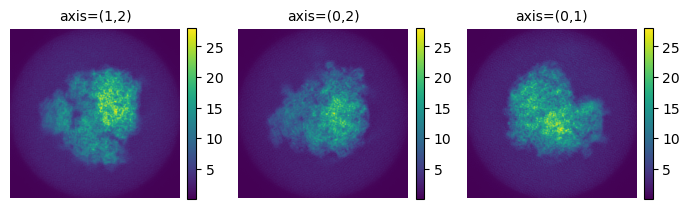

(80, 80, 80)
5.309999942779541


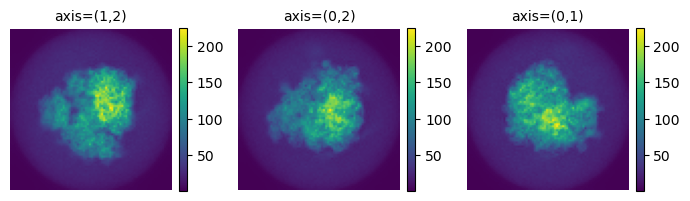

In [32]:
### Load the mrcfile and mask
### apply the mask, then downsample to volume

### EV: could crop the volume before downsampling
### EV: what about positive/negative value maps? (usually standardized??)

# data_file = 'Data/emd_11657.map'  # this volume has symmetry (?), a bit difficult
# mask_file = 'Data/emd_11657_msk_1.map'

data_file = 'Data/emd_2858.map'

mask = False

with mrcfile.open(data_file) as mrc:
    F = mrc.data
    voxel = mrc.voxel_size.x
    mrc.close()

if mask:
    with mrcfile.open(mask_file) as mrc:
        mask = mrc.data
        mrc.close()
    F = F * mask

print(np.amin(F), np.amax(F), '\n')
F = np.where(F>0, F, 0)

print(F.shape)
print(voxel)
plots.orthogonal_2D_projection_plot(F)

factor = 3  # EV: change this depending on volume size
F = fourier_downsample(F, factor)
voxel = voxel * factor

print(F.shape)
print(voxel)
plots.orthogonal_2D_projection_plot(F)

omega = 4.625122517784973
alpha = 2.181661564992912
beta = 0.2617993877991494




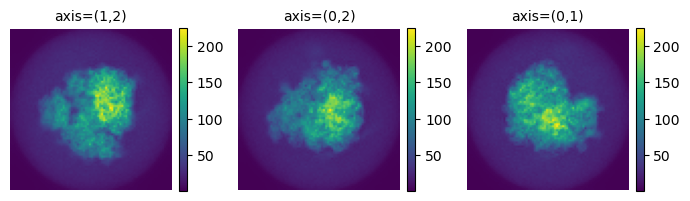

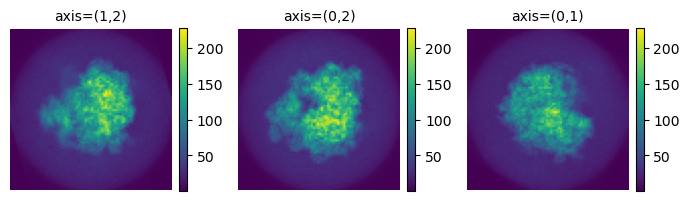

In [33]:
np.random.seed(10)

M = F.shape[0]    # grid size LxLxL
d = 3             # dimensons

## Rotates the structure F by random angles to produce structure G
omega = np.deg2rad(np.random.randint(0,360))
alpha = np.deg2rad(np.random.randint(0,360))
beta = np.deg2rad(np.random.randint(0,180))

# R_gt = transforms.rotate_zyz(omega, beta, alpha)
print('omega =', omega)
print('alpha =', alpha)
print('beta =', beta)
print('\n')

# G = transforms.rotate_voxel_zyz(F, omega, beta, alpha, order=1)
G = transforms.rotate_voxel_zyz_fourier(F, omega, beta, alpha)
                                       
plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(G)

# ### Data preprocessing 
# ### TODO: CHANGE THESE THINGS TO MORE ACCURATE ROTATIONS (BECAUSE THIS GIVES ERRORS
# ### EVEN WITH GROUND TRUTH ROTATIONS). OPTIONS: 1) ASPIRE 2) SPHERICAL BESSEL EXACT STUFF

# ### EV: also note that alignment can only be accurate up to discretization

# t = time.time()
# F = signals.Signal(f, d=3).preprocess_signals()[0]
# # print('\nRotated Volume\n')
# G = transforms.rotate_voxel_zyz(F, omega, beta, alpha, order=1)
# G = signals.Signal(G, d=3).preprocess_signals()[0]
# print('mass = ', np.sum(F), '\n') 
# F_icdf = transforms.Transform(F, d=3, apply_ramp=False).inverse_cdf_transform()
# G_icdf = transforms.Transform(G, d=3, apply_ramp=False).inverse_cdf_transform()
# print('ICDF transforms: ', time.time() - t)

In [34]:
max_l = M//2
# max_l = M//4

fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

t1 = time.time()
# c = alignments.align_sc(F, G, fle)
# c = alignments.align_sw(F, G, fle)
c = alignments.align_rfsw(F, G, fle)
print("Timing of align:", time.time()-t1, '\n')

c2 = transforms.rotation_matrix_from_zyz(omega, beta, alpha)

print(c)
print(c2.T)
print('\n')
print(np.linalg.norm(c-c2.T)/np.linalg.norm(c))

Timing of align: 4.3669750690460205 

[[ 0.87308551  0.48657213  0.03113294]
 [-0.46195708  0.84596003 -0.26635933]
 [-0.15594025  0.21817238  0.96337088]]
[[ 0.86432202  0.50243268  0.02255757]
 [-0.48053023  0.83821969 -0.25783416]
 [-0.14845251  0.21201215  0.96592583]]


0.018073817833816355


RELATIVE ERROR:  0.33847582100370205


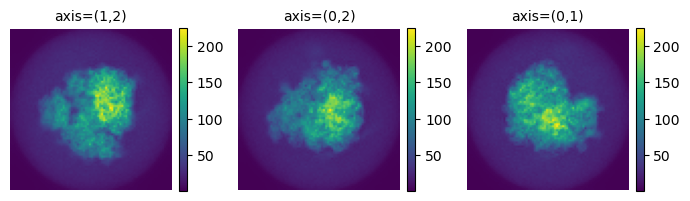

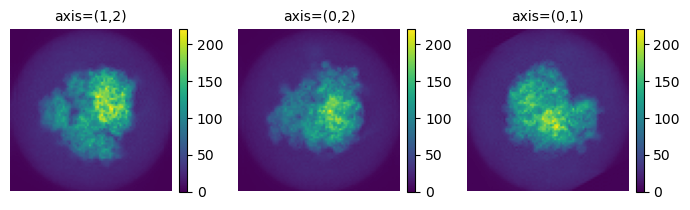

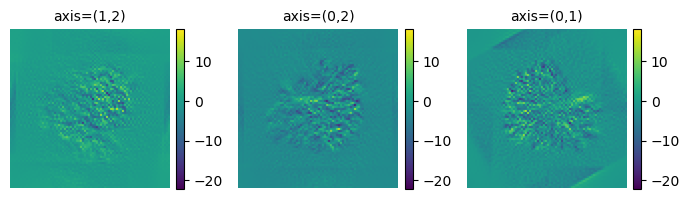

In [35]:
# rotated = transforms.rotate_voxels_3d(G, c2.T)  # use the GT rotations
# rotated = transforms.rotate_voxels_3d(G, c)

o_est, b_est, a_est = Rotation.from_matrix(c.T).as_euler('zyz')

rotated = transforms.rotate_voxel_zyz_fourier(G, -a_est, -b_est, -o_est)

print("RELATIVE ERROR: ", np.linalg.norm(F - rotated) / np.linalg.norm(F))

plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(rotated)
plots.orthogonal_2D_projection_plot(F-rotated)

In [38]:
# g_est, b_est, a_est = transforms.rotmat_to_euler_zyz(c.T)  # EV: should be same, need to modify frame

print('ground truth: ' , np.rad2deg([omega, beta, alpha]))

print('    estimate: ', np.round( np.rad2deg(transforms.rotmat_to_euler_zyz(c.T)) , 1))

# print('    estimate: ', np.round( np.rad2deg( [o_est, b_est, a_est] ) , 1))

ground truth:  [265.  15. 125.]
    estimate:  [125.6  15.6 -96.7]


In [39]:
-96 + 360

264

In [9]:
# 172 + 180, 180 - 117, 47 + 180

---

### test non-overlapping volumnes

---

omega = 3.001966313430247
alpha = 0.8203047484373349
beta = 2.0420352248333655




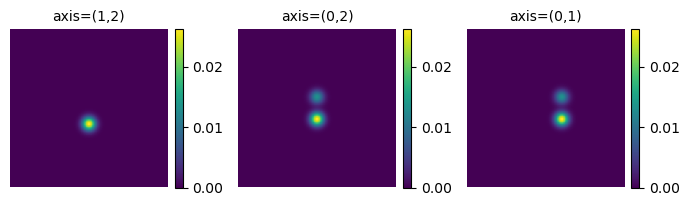

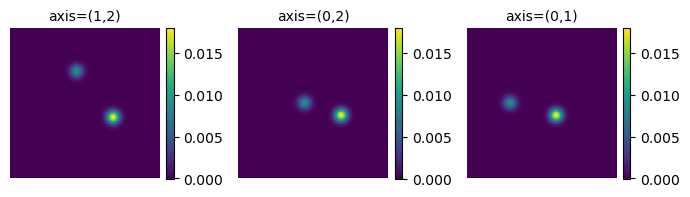

In [10]:
### EV: test non-overlappinig volumes
###     need better volume than this though

np.random.seed(0)

M = 100
d = 3
sigma = 3

z = utils.generate_centered_gaussian(M, d=d, sigma=sigma)

F = transforms.translate_3d(z, 7, 10, 0)
F += transforms.translate_3d(z, -7, 10, 0) * 0.5  # EV: using  *0.5 --> bad alignment?

G = transforms.translate_3d(z, 20, 10, 0)
G += transforms.translate_3d(z, -20, 10, 0) * 0.5

omega = np.deg2rad(np.random.randint(0,360))
alpha = np.deg2rad(np.random.randint(0,360))
beta = np.deg2rad(np.random.randint(0,180))

print('omega =', omega)
print('alpha =', alpha)
print('beta =', beta)
print('\n')

# G = transforms.rotate_voxel_zyz(G, omega, beta, alpha, order=1)
G = transforms.rotate_voxel_zyz_fourier(G, omega, beta, alpha)

plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(G)

In [11]:
max_l = M//2
# max_l = M//4

fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

t1 = time.time()
# c = alignments.align_sc(F, G, fle)
c = alignments.align_sw(F, G, fle)
# c = alignments.align_rfsw(F, G, fle)
print("Timing of align:", time.time()-t1, '\n')

c2 = transforms.rotation_matrix_from_zyz(omega, beta, alpha)

print(c)
print(c2.T)
print('\n')
print(np.linalg.norm(c-c2.T)/np.linalg.norm(c))

Timing of align: 5.389382839202881 

[[ 0.08345905  0.44586565  0.89120055]
 [ 0.8991308  -0.41928206  0.12556418]
 [ 0.42964915  0.79082639 -0.43588442]]
[[ 0.20482281  0.42371219  0.88233531]
 [ 0.7673271  -0.62915188  0.12400414]
 [ 0.60766499  0.65164092 -0.4539905 ]]


0.20664670592616766


RELATIVE ERROR:  1.3947195239662744


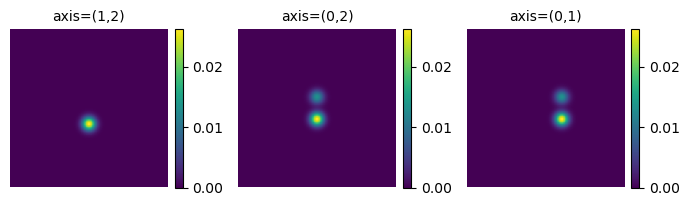

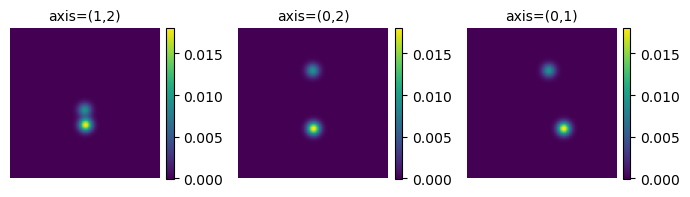

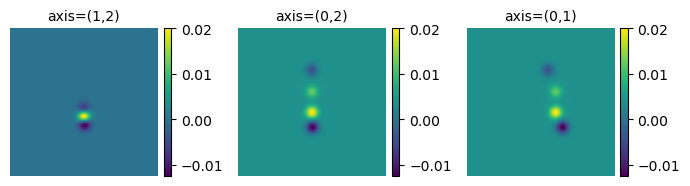

In [12]:
o_est, b_est, a_est = Rotation.from_matrix(c.T).as_euler('zyz')

rotated = transforms.rotate_voxel_zyz_fourier(G, -a_est, -b_est, -o_est)

print("RELATIVE ERROR: ", np.linalg.norm(F - rotated) / np.linalg.norm(F))

plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(rotated)
plots.orthogonal_2D_projection_plot(F-rotated)
# print('\n')
# plots.orthogonal_2D_projection_plot(F - G)

In [13]:
# g_est, b_est, a_est = transforms.rotmat_to_euler_zyz(c.T)  # EV: should be same, need to modify frame
# print('    estimate: ', np.round( np.rad2deg(transforms.rotmat_to_euler_zyz(c.T)) , 1))

print('ground truth: ' , np.rad2deg([omega, beta, alpha]))

print('    estimate: ', np.round( np.rad2deg( [o_est, b_est, a_est] ) , 1))

ground truth:  [172. 117.  47.]
    estimate:  [172.  115.8  61.5]


In [14]:
# np.linalg.norm(F) * 2, np.linalg.norm(F) + np.linalg.norm(G), np.linalg.norm(F - G)

---

### test simulated heterogeneity cryo-EM volumes

---

/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:206: RuntimeWarning: Map ID string not found - not an MRC file, or file is corrupt
  warnings.warn(msg, RuntimeWarning)
/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:216: RuntimeWarning: Unrecognised machine stamp: 0x00 0x00 0x00 0x00
  warnings.warn(str(err), RuntimeWarning)


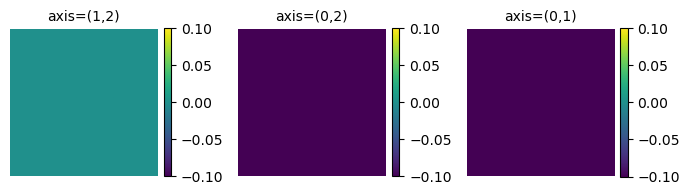

In [42]:
file1 = 'Data/het_models/0.mrc'   # first volume
# file2 = 'Data/het_models/20.mrc'
file2 = 'Data/het_models/0.mrc'

with mrcfile.open(file1, permissive=True) as mrc:
    F = mrc.data
    mrc.close()

with mrcfile.open(file2, permissive=True) as mrc:
    G = mrc.data
    mrc.close()

plots.orthogonal_2D_projection_plot(F - G)

omega = 2.9321531433504737
alpha = 0.2617993877991494
beta = 1.2566370614359172




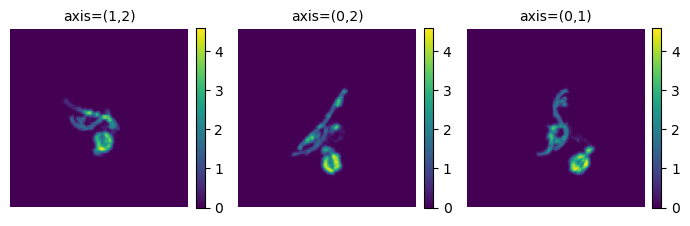

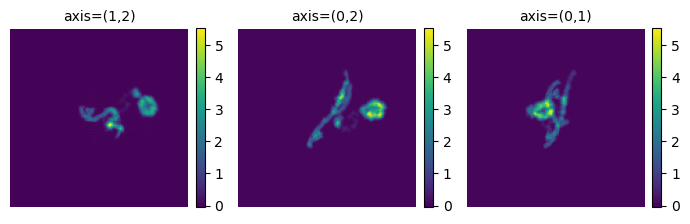

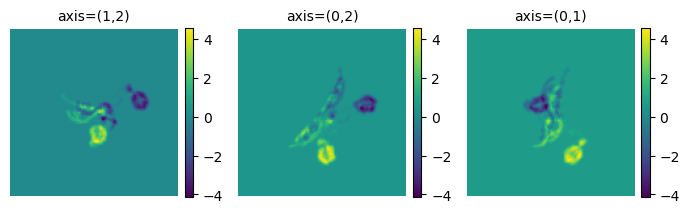

In [43]:
np.random.seed(2)

M = F.shape[0]    # grid size LxLxL
d = 3             # dimensons

## Rotates the structure F by random angles to produce structure G
omega = np.deg2rad(np.random.randint(0,360))
alpha = np.deg2rad(np.random.randint(0,360))
beta = np.deg2rad(np.random.randint(0,180))

print('omega =', omega)
print('alpha =', alpha)
print('beta =', beta)
print('\n')

# G = transforms.rotate_voxel_zyz(G, omega, beta, alpha, order=1)
G = transforms.rotate_voxel_zyz_fourier(G, omega, beta, alpha)

# G_rot = G.copy().astype('float32')
# with mrcfile.new('Output/vol_20_rot.mrc', overwrite=True) as mrc:
#     mrc.set_data(G_rot)

# F = signals.Signal(v1, d=3).preprocess_signals()[0]
# G = signals.Signal(G, d=3).preprocess_signals()[0]
# print('mass = ', np.sum(F), '\n') 

# t = time.time()
# F_icdf = transforms.Transform(F, d=3, apply_ramp=False).inverse_cdf_transform()
# G_icdf = transforms.Transform(G, d=3, apply_ramp=False).inverse_cdf_transform()
# print('ICDF transforms: ', time.time() - t)

plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(G)
plots.orthogonal_2D_projection_plot(F - G)

In [44]:
max_l = M//2
# max_l = M//4

fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

t1 = time.time()
c = alignments.align_sw(F, G, fle)
# c = alignments.align_rfsw(F, G, fle)
print("Timing of align:", time.time()-t1, '\n')

c2 = transforms.rotation_matrix_from_zyz(omega, beta, alpha)

print(c)
print(c2.T)
print('\n')
print(np.linalg.norm(c-c2.T)/np.linalg.norm(c))

Timing of align: 9.969253063201904 

[[-0.35769764  0.11892219  0.92623426]
 [ 0.18333007 -0.9636139   0.19452077]
 [ 0.91566505  0.23938621  0.3228804 ]]
[[-0.34577633  0.12259553  0.93027365]
 [ 0.19110419 -0.9614467   0.19773577]
 [ 0.91865005  0.24615154  0.30901699]]


0.012835777134969856


RELATIVE ERROR:  0.21566472043381532


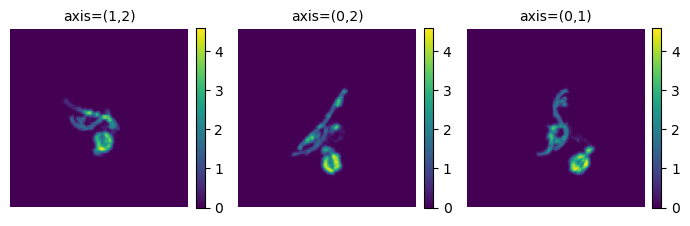

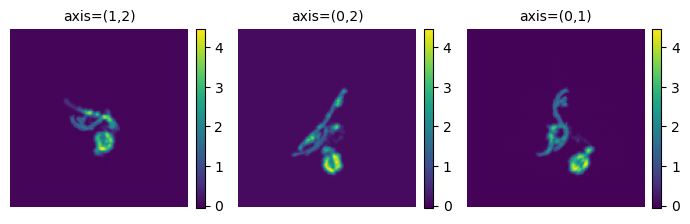

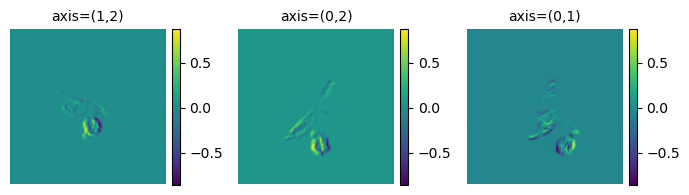

In [45]:
o_est, b_est, a_est = Rotation.from_matrix(c.T).as_euler('zyz')

rotated = transforms.rotate_voxel_zyz_fourier(G, -a_est, -b_est, -o_est)

print("RELATIVE ERROR: ", np.linalg.norm(F - rotated) / np.linalg.norm(F))

plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(rotated)
plots.orthogonal_2D_projection_plot(F-rotated)

In [46]:
# g_est, b_est, a_est = transforms.rotmat_to_euler_zyz(c.T)
# print('ground truth: ' , np.rad2deg([omega, beta, alpha]))
# print('    estimate: ', np.round( np.rad2deg(transforms.rotmat_to_euler_zyz(c.T)) , 1))

print('ground truth: ' , np.rad2deg([omega, beta, alpha]))

print('    estimate: ', np.round( np.rad2deg( [o_est, b_est, a_est] ) , 1))

ground truth:  [168.  72.  15.]
    estimate:  [168.1  71.2  14.7]


In [47]:
# with mrcfile.new('Output/vol_20_rot_aligned_rfsw.mrc', overwrite=True) as mrc:
#     mrc.set_data(rotated.astype('float32'))

In [48]:
c

array([[-0.35769764,  0.11892219,  0.92623426],
       [ 0.18333007, -0.9636139 ,  0.19452077],
       [ 0.91566505,  0.23938621,  0.3228804 ]])

In [ ]:
z = 